<a href="https://colab.research.google.com/github/LetheeshBalaji/DEEP-LEARNING/blob/main/DL_self_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploring Word Representations: From Traditional Word Embeddings to Transformers
**Course:** 24ADI306 Deep Learning &nbsp;|&nbsp; **Assignment:** Self Learning Assignment 1 (CO3, K3–K4)  
**Student:** Letheesh Balaji (24BAD063) &nbsp;|&nbsp; Dept. of AI & Data Science, Kumaraguru College of Technology

**Goal.** Represent the *same* text corpus with progressively richer techniques and compare them:

| Family | Technique used in this notebook |
|---|---|
| Traditional (sparse, count-based) | One-Hot, Bag of Words, N-grams, **TF-IDF** |
| Matrix factorisation | Co-occurrence → PPMI → **SVD / LSA** (the "additional" technique) |
| Predictive static embeddings | **Word2Vec** (Skip-gram + CBOW) |
| Pretrained / sub-word static | **GloVe** (pretrained), **FastText** (trained here) |
| Neural embeddings | **TensorFlow / Keras `Embedding` layer** |
| Contextual embeddings | **BERT** (pretrained Transformer) |
| Visualisation | PCA, t-SNE, UMAP, TensorFlow Embedding Projector (TSV export) |

**Common dataset:** NLTK **Reuters-21578** newswire corpus (10,788 documents, ~1.7 M tokens).
It is a real, domain-rich corpus (oil, grain, currencies, banking, countries) so semantic neighbours are easy to judge.

## 0. Setup
Runs on Google Colab (free CPU is enough). `gensim` and `umap-learn` are the only extra installs.

In [1]:
%pip install -q gensim umap-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 64.2 MB/s eta 0:00:00


In [2]:
import os, time, json, re, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import TSNE
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
os.makedirs("outputs/projector", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
timing = {}      # training / build time per technique (seconds)
RESULTS = {}     # everything the report needs

## 1. Common dataset: Reuters-21578 (NLTK)
**Pre-processing:** lower-case → keep alphabetic tokens (length > 2) → remove English stop-words and a few Reuters boilerplate tokens
(`said, mln, dlrs, pct, cts, lt, vs, reuter …`). Every technique below sees exactly the same token lists.

In [3]:
import nltk
nltk.download("reuters", quiet=True); nltk.download("stopwords", quiet=True)
from nltk.corpus import reuters, stopwords

STOP = set(stopwords.words("english")) | {"said","would","mln","dlrs","pct","cts","lt","vs","reuter","also","will","year"}
def clean(tokens):
    return [w.lower() for w in tokens if w.isalpha() and len(w) > 2 and w.lower() not in STOP]

fileids = reuters.fileids()
docs, labels = [], []
for f in fileids:
    t = clean(reuters.words(f))
    if len(t) >= 10:
        docs.append(t)
        cats = reuters.categories(f)
        labels.append(cats[0] if len(cats) == 1 else None)   # single-label docs only (used later for Keras)
texts = [" ".join(d) for d in docs]

n_tokens = sum(len(d) for d in docs)
print(f"Documents: {len(docs):,} | tokens after cleaning: {n_tokens:,} | vocabulary: {len(set(w for d in docs for w in d)):,}")
print("Example (first 25 tokens):", docs[0][:25])
RESULTS["dataset"] = dict(docs=len(docs), tokens=n_tokens, vocab=len(set(w for d in docs for w in d)))

Documents: 10,596 | tokens after cleaning: 740,568 | vocabulary: 28,642
Example (first 25 tokens): ['asian', 'exporters', 'fear', 'damage', 'japan', 'rift', 'mounting', 'trade', 'friction', 'japan', 'raised', 'fears', 'among', 'many', 'asia', 'exporting', 'nations', 'row', 'could', 'inflict', 'far', 'reaching', 'economic', 'damage', 'businessmen']


### Helper: one container for every embedding
All methods are wrapped in the same small class so that cosine-similarity search, the top-5 neighbour tables and the evaluation use **identical code**.
Cosine similarity is $\cos(a,b)=\dfrac{a\cdot b}{\lVert a\rVert\,\lVert b\rVert}$; rows are L2-normalised once, so a dot product equals the cosine.

In [4]:
class Emb:
    '''A word -> vector table with cosine nearest-neighbour search (works for sparse and dense matrices).'''
    def __init__(self, name, words, M):
        self.name, self.words = name, list(words)
        self.idx = {w: i for i, w in enumerate(self.words)}
        self.M = normalize(M)                      # L2-normalise rows
        self.dim = M.shape[1]
    def __contains__(self, w): return w in self.idx
    def nn(self, w, k=5, candidates=None):
        i = self.idx[w]
        s = self.M[i].dot(self.M.T)
        s = (s.toarray() if sparse.issparse(s) else np.asarray(s)).ravel().astype(float)
        s[i] = -np.inf
        if candidates is not None:                 # restrict the search to a candidate word list
            keep = np.full(len(s), -np.inf); ids = [self.idx[c] for c in candidates if c in self.idx and c != w]
            keep[ids] = s[ids]; s = keep
        top = np.argsort(-s)[:k]
        return [(self.words[j], float(s[j])) for j in top]

EMB = {}   # name -> Emb
QUERY = ["oil", "bank", "dollar", "wheat", "japan", "trade"]

def neighbour_table(names, queries=QUERY, k=5):
    rows = []
    for q in queries:
        row = {"query": q}
        for n in names:
            row[n] = ", ".join(f"{w} ({s:.2f})" for w, s in EMB[n].nn(q, k)) if q in EMB[n] else "—"
        rows.append(row)
    return pd.DataFrame(rows).set_index("query")

## 2. Traditional text representations
**Concepts**
- **One-Hot** – each word is a vector with a single 1; length = vocabulary size. No notion of similarity (every pair is orthogonal).
- **Bag of Words (BoW)** – a document is the vector of word counts. Ignores order; frequent words dominate.
- **N-grams** – BoW over word pairs/triples; recovers a little local order (*"interest rate"*) at the cost of a much bigger vocabulary.
- **TF-IDF** – re-weights counts: $\text{tfidf}(t,d)=\text{tf}(t,d)\cdot\log\frac{N}{df(t)}$, so words that are common across all documents are down-weighted.

All of these are **sparse, high-dimensional and context-free**.

In [5]:
# 2.1 One-hot encoding on a toy vocabulary
toy = ["oil prices rise", "oil exports fall", "bank raises rates"]
vocab_toy = sorted({w for s in toy for w in s.split()})
onehot = pd.DataFrame(np.eye(len(vocab_toy), dtype=int), index=vocab_toy, columns=vocab_toy)
print(onehot)
a, b = onehot.loc["oil"].values, onehot.loc["prices"].values
print("\ncosine(oil, prices) =", a @ b, "  -> one-hot vectors of different words are always orthogonal")

         bank  exports  fall  oil  prices  raises  rates  rise
bank        1        0     0    0       0       0      0     0
exports     0        1     0    0       0       0      0     0
fall        0        0     1    0       0       0      0     0
oil         0        0     0    1       0       0      0     0
prices      0        0     0    0       1       0      0     0
raises      0        0     0    0       0       1      0     0
rates       0        0     0    0       0       0      1     0
rise        0        0     0    0       0       0      0     1

cosine(oil, prices) = 0   -> one-hot vectors of different words are always orthogonal


In [6]:
# 2.2 Bag of Words and N-grams on the full corpus
t0 = time.time()
bow = CountVectorizer(min_df=5, max_features=10000)
X_bow = bow.fit_transform(texts)
ng = CountVectorizer(ngram_range=(1, 2), min_df=10, max_features=20000)
X_ng = ng.fit_transform(texts)
print("BoW     :", X_bow.shape, f"sparsity = {1 - X_bow.nnz / np.prod(X_bow.shape):.2%}")
print("1+2-gram:", X_ng.shape)
freq = np.asarray(X_ng.sum(0)).ravel()
top_bi = [(f, int(c)) for f, c in sorted(zip(ng.get_feature_names_out(), freq), key=lambda x: -x[1]) if " " in f][:8]
print("Most frequent bigrams:", top_bi)
timing["BoW + N-grams"] = time.time() - t0
RESULTS["bow"] = dict(shape=list(X_bow.shape), sparsity=float(1 - X_bow.nnz / np.prod(X_bow.shape)), ngram_shape=list(X_ng.shape))

BoW     : (10596, 8312) sparsity = 99.46%
1+2-gram: (10596, 10483)
Most frequent bigrams: [('shr net', 1401), ('net revs', 1216), ('avg shrs', 1046), ('per share', 1030), ('net shr', 1010), ('net loss', 961), ('shr loss', 873), ('loss loss', 866)]


In [7]:
# 2.3 TF-IDF  (document x term matrix)
t0 = time.time()
tfidf = TfidfVectorizer(min_df=5, max_features=10000, sublinear_tf=True)
X_tfidf = tfidf.fit_transform(texts)                       # (docs, terms)
timing["TF-IDF"] = time.time() - t0
print("TF-IDF matrix:", X_tfidf.shape)

# highest-weighted terms of one document
terms = tfidf.get_feature_names_out()
row = X_tfidf[3].toarray().ravel()
print("Top TF-IDF terms in document 3:", [terms[i] for i in row.argsort()[::-1][:8]])

# A word's TF-IDF vector = its column (weight in every document) -> words used in the same documents get similar vectors
EMB["TF-IDF"] = Emb("TF-IDF", terms, X_tfidf.T.tocsr())
RESULTS["tfidf_dim"] = X_tfidf.shape[0]
neighbour_table(["TF-IDF"])

TF-IDF matrix: (10596, 8312)
Top TF-IDF terms in document 3: ['baht', 'thailand', 'registering', 'quarter', 'canned', 'billion', 'widens', 'first']


,TF-IDF
query,
oil,"crude (0.45), barrels (0.40), gas (0.38), barr..."
bank,"money (0.43), england (0.38), central (0.37), ..."
dollar,"yen (0.41), currency (0.36), dealers (0.33), t..."
wheat,"tonnes (0.40), agriculture (0.35), soft (0.34)..."
japan,"japanese (0.43), yen (0.40), tokyo (0.32), tra..."
trade,"deficit (0.40), surplus (0.39), tariffs (0.35)..."


## 3. Matrix-factorisation embeddings: Co-occurrence → PPMI → SVD (LSA)  *(the "additional" technique)*
1. Count how often word *i* appears within ±5 words of word *j* (distance-weighted) → **co-occurrence matrix**.
2. Convert counts to **PPMI** (positive pointwise mutual information) so very frequent words do not dominate.
3. **Truncated SVD** compresses the huge sparse matrix to 100 dense dimensions (this is the idea behind **LSA**).

In [8]:
t0 = time.time()
V = 8000
from collections import Counter
cnt = Counter(w for d in docs for w in d)
vocab_ppmi = [w for w, _ in cnt.most_common(V)]
w2i = {w: i for i, w in enumerate(vocab_ppmi)}

WIN = 5
rows, cols, vals = [], [], []
for d in docs:
    ids = [w2i[w] for w in d if w in w2i]
    ids = np.array(ids)
    for k in range(1, WIN + 1):
        if len(ids) > k:
            rows.append(ids[:-k]); cols.append(ids[k:]); vals.append(np.full(len(ids) - k, 1.0 / k))
rows, cols, vals = map(np.concatenate, (rows, cols, vals))
C = sparse.coo_matrix((vals, (rows, cols)), shape=(V, V)).tocsr()
C = C + C.T                                                      # symmetric window

total = C.sum(); rs = np.asarray(C.sum(1)).ravel(); cs = np.asarray(C.sum(0)).ravel() ** 0.75
cs = cs / cs.sum() * total                                       # context-distribution smoothing (alpha = 0.75)
C = C.tocoo()
pmi = np.log((C.data * total) / (rs[C.row] * cs[C.col]) + 1e-12)
ppmi = sparse.coo_matrix((np.maximum(pmi, 0), (C.row, C.col)), shape=(V, V)).tocsr()
ppmi.eliminate_zeros()

svd = TruncatedSVD(n_components=100, random_state=SEED)
U = svd.fit_transform(ppmi)
timing["PPMI + SVD (LSA)"] = time.time() - t0
EMB["LSA (PPMI+SVD)"] = Emb("LSA (PPMI+SVD)", vocab_ppmi, U)
print(f"Co-occurrence matrix {C.shape}, PPMI non-zeros = {ppmi.nnz:,}; SVD explained variance = {svd.explained_variance_ratio_.sum():.1%}")
neighbour_table(["LSA (PPMI+SVD)"])

Co-occurrence matrix (8000, 8000), PPMI non-zeros = 2,024,152; SVD explained variance = 14.3%


,LSA (PPMI+SVD)
query,
oil,"crude (0.81), petroleum (0.73), barrels (0.71)..."
bank,"banks (0.79), lending (0.73), chartered (0.72)..."
dollar,"yen (0.91), currency (0.87), currencies (0.80)..."
wheat,"barley (0.88), corn (0.83), durum (0.79), flou..."
japan,"japanese (0.88), tokyo (0.80), chip (0.78), ch..."
trade,"yeutter (0.84), bilateral (0.78), tariffs (0.7..."


## 4. Word2Vec — CBOW and Skip-gram (predictive static embeddings)
**Idea.** Train a shallow network on a *fake* task; the learned weight matrix is the embedding.
- **CBOW**: predict the *centre* word from the average of its context words (fast, good for frequent words).
- **Skip-gram**: predict each *context* word from the centre word (slower, better for rare words).

Training uses **negative sampling**: for every true (centre, context) pair, a few random "noise" words are pushed away, so the model avoids a full-vocabulary softmax.

In [9]:
# Toy illustration of the training examples each architecture sees (window = 2)
sent = "oil prices rise sharply today".split(); W = 2
print("Skip-gram pairs (centre -> context):")
print([(sent[i], sent[j]) for i in range(len(sent)) for j in range(max(0, i - W), min(len(sent), i + W + 1)) if j != i][:8], "...")
print("\nCBOW examples (context -> centre):")
for i in range(len(sent)):
    print([sent[j] for j in range(max(0, i - W), min(len(sent), i + W + 1)) if j != i], "->", sent[i])

Skip-gram pairs (centre -> context):
[('oil', 'prices'), ('oil', 'rise'), ('prices', 'oil'), ('prices', 'rise'), ('prices', 'sharply'), ('rise', 'oil'), ('rise', 'prices'), ('rise', 'sharply')] ...

CBOW examples (context -> centre):
['prices', 'rise'] -> oil
['oil', 'rise', 'sharply'] -> prices
['oil', 'prices', 'sharply', 'today'] -> rise
['prices', 'rise', 'today'] -> sharply
['rise', 'sharply'] -> today


In [10]:
from gensim.models import Word2Vec, FastText
import multiprocessing
WORKERS = max(1, multiprocessing.cpu_count() - 0)

t0 = time.time()
w2v_sg = Word2Vec(docs, vector_size=100, window=5, min_count=5, sg=1, negative=10, epochs=15, workers=WORKERS, seed=SEED)
timing["Word2Vec skip-gram"] = time.time() - t0
t0 = time.time()
w2v_cb = Word2Vec(docs, vector_size=100, window=5, min_count=5, sg=0, negative=10, epochs=15, workers=WORKERS, seed=SEED)
timing["Word2Vec CBOW"] = time.time() - t0

EMB["Word2Vec (skip-gram)"] = Emb("Word2Vec (skip-gram)", w2v_sg.wv.index_to_key, w2v_sg.wv.vectors)
EMB["Word2Vec (CBOW)"]      = Emb("Word2Vec (CBOW)",      w2v_cb.wv.index_to_key, w2v_cb.wv.vectors)
print(f"vocabulary = {len(w2v_sg.wv):,} words | skip-gram {timing['Word2Vec skip-gram']:.0f}s, CBOW {timing['Word2Vec CBOW']:.0f}s")
neighbour_table(["Word2Vec (skip-gram)", "Word2Vec (CBOW)"])

vocabulary = 10,120 words | skip-gram 114s, CBOW 19s


,Word2Vec (skip-gram),Word2Vec (CBOW)
query,,
oil,"crude (0.75), petroleum (0.60), condensate (0....","petroleum (0.61), natural (0.55), crudes (0.52..."
bank,"banks (0.70), central (0.64), satoshi (0.62), ...","banks (0.66), bankers (0.58), governor (0.48),..."
dollar,"currencies (0.72), yen (0.68), currency (0.65)...","currencies (0.60), sterling (0.57), mark (0.55..."
wheat,"barley (0.73), durum (0.69), corn (0.68), usda...","corn (0.69), grains (0.66), barley (0.66), arg..."
japan,"japanese (0.70), chipmakers (0.62), reneging (...","japanese (0.62), tokyo (0.53), chip (0.51), wa..."
trade,"counterpart (0.66), outlining (0.63), channon ...","yeutter (0.54), clercq (0.51), invisibles (0.5..."


In [11]:
# Semantic relationships: similarity scores and vector arithmetic
for a, b in [("oil", "crude"), ("wheat", "corn"), ("dollar", "yen"), ("oil", "wheat"), ("bank", "banana" if "banana" in w2v_sg.wv else "zinc")]:
    print(f"cos({a:7s}, {b:7s}) = {w2v_sg.wv.similarity(a, b):.3f}")
print()
for pos, neg in [(["dollar", "japan"], ["us"]), (["crude", "wheat"], ["oil"])]:
    if all(w in w2v_sg.wv for w in pos + neg):
        print(f"{' + '.join(pos)} - {' - '.join(neg)}  ->", [(w, round(s, 2)) for w, s in w2v_sg.wv.most_similar(positive=pos, negative=neg, topn=3)])

cos(oil    , crude  ) = 0.746
cos(wheat  , corn   ) = 0.681
cos(dollar , yen    ) = 0.681
cos(oil    , wheat  ) = 0.284
cos(bank   , zinc   ) = 0.215

crude + wheat - oil  -> [('barley', 0.65), ('flour', 0.62), ('corn', 0.61)]


## 5. FastText and GloVe
- **GloVe** (pretrained, Stanford) factorises *global* co-occurrence statistics; we load the 100-d vectors trained on Wikipedia + Gigaword (400 K words).
- **FastText** represents a word as the **sum of its character n-gram vectors** (e.g. `oilfields` → `<oi, oil, ilf, …`), so it can build a vector for a word it never saw in training.

In [12]:
t0 = time.time()
ft = FastText(docs, vector_size=100, window=5, min_count=5, sg=1, negative=10, epochs=15, min_n=3, max_n=6, workers=WORKERS, seed=SEED)
timing["FastText"] = time.time() - t0
EMB["FastText"] = Emb("FastText", ft.wv.index_to_key, ft.wv.vectors)
print(f"FastText trained in {timing['FastText']:.0f}s | vocabulary = {len(ft.wv):,}")
neighbour_table(["FastText"])

FastText trained in 118s | vocabulary = 10,120


,FastText
query,
oil,"crude (0.68), barrels (0.62), unocal (0.62), c..."
bank,"banks (0.72), bankverein (0.71), bankhaus (0.6..."
dollar,"dollars (0.71), currencies (0.70), eurodollar ..."
wheat,"wheats (0.88), barley (0.74), corn (0.68), eep..."
japan,"japanese (0.78), microchips (0.64), microchip ..."
trade,"yeutter (0.65), bilateral (0.64), countertrade..."


In [13]:
import gensim.downloader as api
t0 = time.time()
glove = api.load("glove-wiki-gigaword-100")                # ~130 MB download, cached afterwards
timing["GloVe (load pretrained)"] = time.time() - t0
EMB["GloVe (pretrained)"] = Emb("GloVe (pretrained)", glove.index_to_key, glove.vectors)
print(f"GloVe: {len(glove):,} words x {glove.vector_size} dims")
print("king - man + woman ->", glove.most_similar(positive=["king", "woman"], negative=["man"], topn=3))
neighbour_table(["GloVe (pretrained)"])

[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe: 400,000 words x 100 dims
king - man + woman -> [('queen', 0.7698540687561035), ('monarch', 0.6843381524085999), ('throne', 0.6755736470222473)]


,GloVe (pretrained)
query,
oil,"petroleum (0.79), crude (0.78), gas (0.76), fu..."
bank,"banks (0.81), banking (0.75), credit (0.70), i..."
dollar,"currency (0.76), greenback (0.73), euro (0.73)..."
wheat,"corn (0.88), grain (0.85), maize (0.82), soybe..."
japan,"japanese (0.80), korea (0.77), tokyo (0.75), c..."
trade,"export (0.71), economic (0.71), trading (0.71)..."


### 5.1 Out-of-vocabulary (OOV) words: Word2Vec vs FastText
We pick real-looking words that **do not occur** in the Reuters vocabulary (inflected / compound forms and a typo).
Word2Vec has no vector for them; FastText assembles one from sub-word pieces.

In [14]:
candidates = ["oilfields", "devaluations", "unprofitability", "wheatgrowers", "bankk", "dollarisation"]
oov = [w for w in candidates if w not in w2v_sg.wv]
print("OOV for Word2Vec:", oov)
rows = []
for w in oov:
    try: w2v_sg.wv[w]; w2v_msg = "has vector"
    except KeyError: w2v_msg = "KeyError (no vector)"
    nn = ft.wv.most_similar(w, topn=5)
    rows.append({"OOV word": w, "Word2Vec": w2v_msg, "FastText top-5 neighbours": ", ".join(f"{a} ({b:.2f})" for a, b in nn)})
oov_df = pd.DataFrame(rows).set_index("OOV word")
oov_df

OOV for Word2Vec: ['devaluations', 'unprofitability', 'wheatgrowers', 'bankk', 'dollarisation']


,Word2Vec,FastText top-5 neighbours
OOV word,,
devaluations,KeyError (no vector),"devaluation (0.96), revaluation (0.86), evalua..."
unprofitability,KeyError (no vector),"profitability (0.94), unprofitable (0.80), pro..."
wheatgrowers,KeyError (no vector),"growers (0.89), wheat (0.79), wheats (0.77), g..."
bankk,KeyError (no vector),"bank (0.87), bankhaus (0.82), bankeast (0.81),..."
dollarisation,KeyError (no vector),"stabilisation (0.75), rationalisation (0.74), ..."


In [15]:
# Same idea inside GloVe: it is a fixed word list, so OOV words simply fail
print([w for w in oov if w not in glove][:6], "-> not in the GloVe vocabulary either (static lookup table).")
RESULTS["oov"] = oov_df.reset_index().to_dict("records")

['wheatgrowers', 'bankk', 'dollarisation'] -> not in the GloVe vocabulary either (static lookup table).


## 6. Neural embeddings with TensorFlow / Keras
`keras.layers.Embedding(vocab_size, dim)` is a **trainable lookup table**: integer word-id → dense vector. Unlike Word2Vec, its vectors are optimised for a *downstream task*.
We train it as part of a small **news-topic classifier** (7 most common single-label Reuters topics) and then inspect the learned vectors.
Architecture: `TextVectorization → Embedding(50) → GlobalAveragePooling → Dense(softmax)`.

In [16]:
import tensorflow as tf
from tensorflow import keras
from keras import layers
tf.random.set_seed(SEED)

# (a) what the layer does
demo = layers.Embedding(input_dim=1000, output_dim=5)
print("Embedding of word ids [3, 7, 3]:\n", demo(tf.constant([[3, 7, 3]])).numpy().round(3))
print("Weight matrix shape:", demo.weights[0].shape, "(vocab_size x embedding_dim) — ids 3 and 3 give the same row")

Embedding of word ids [3, 7, 3]:
 [[[ 0.027 -0.048 -0.031  0.001 -0.043]
  [-0.038  0.023 -0.032  0.018  0.015]
  [ 0.027 -0.048 -0.031  0.001 -0.043]]]
Weight matrix shape: (1000, 5) (vocab_size x embedding_dim) — ids 3 and 3 give the same row


In [17]:
# (b) topic classifier
top_topics = [t for t, _ in Counter(l for l in labels if l).most_common(7)]
sel = [i for i, l in enumerate(labels) if l in top_topics]
X_txt = np.array([texts[i] for i in sel], dtype=object); y = np.array([top_topics.index(labels[i]) for i in sel])
perm = np.random.RandomState(SEED).permutation(len(sel)); cut = int(0.8 * len(sel))
tr, va = perm[:cut], perm[cut:]

vec = layers.TextVectorization(max_tokens=10000, output_sequence_length=200)
vec.adapt(X_txt[tr])
model = keras.Sequential([
    keras.Input(shape=(1,), dtype=tf.string),
    vec,
    layers.Embedding(10000, 50, mask_zero=True, name="word_embedding"),
    layers.GlobalAveragePooling1D(),
    layers.Dense(len(top_topics), activation="softmax"),
])
model.compile(optimizer=keras.optimizers.Adam(0.01), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
hist = model.fit(X_txt[tr], y[tr], validation_data=(X_txt[va], y[va]), epochs=12, batch_size=64, verbose=0)
timing["Keras Embedding (12 epochs)"] = time.time() - t0
acc = hist.history["val_accuracy"][-1]
print("Topics:", top_topics)
print(f"Train docs {len(tr)}, validation docs {len(va)} | final val accuracy = {acc:.3f} | time {timing['Keras Embedding (12 epochs)']:.0f}s")
RESULTS["keras"] = dict(topics=top_topics, val_acc=float(acc), train_docs=int(len(tr)), val_docs=int(len(va)),
                        history={k: [float(x) for x in v] for k, v in hist.history.items()})

Topics: ['earn', 'acq', 'crude', 'trade', 'money-fx', 'interest', 'ship']
Train docs 5978, validation docs 1495 | final val accuracy = 0.977 | time 13s


In [18]:
# (c) pull the learned vectors out of the layer and inspect neighbours
kv = vec.get_vocabulary()[2:]                                    # drop padding and [UNK]
kw = model.get_layer("word_embedding").get_weights()[0][2:]
EMB["Keras Embedding"] = Emb("Keras Embedding", kv, kw)
neighbour_table(["Keras Embedding"])

,Keras Embedding
query,
oil,"exxon (0.98), crudes (0.98), opec (0.98), barr..."
bank,"banks (0.95), unlikely (0.92), prompted (0.91)..."
dollar,"currency (0.99), paris (0.98), auctions (0.97)..."
wheat,"pave (0.93), faith (0.93), sudden (0.92), resp..."
japan,"reforms (0.96), moves (0.94), indicators (0.93..."
trade,"israeli (0.98), washington (0.98), practices (..."


## 7. Contextual embeddings with a pretrained Transformer (BERT)
Word2Vec/GloVe/FastText give **one vector per word type**: *bank* (money) and *bank* (river) share a single vector.
BERT runs the whole sentence through 12 self-attention layers, so the vector of a token **depends on its sentence**.

Plan: take the final-layer vector of the target word in several sentences and compare them with cosine similarity.

In [19]:
BERT_OK = False
try:
    import torch
    from transformers import AutoTokenizer, AutoModel
    MODEL_NAME = "bert-base-uncased"
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    bert = AutoModel.from_pretrained(MODEL_NAME).eval()
    BERT_OK = True
    print(MODEL_NAME, "loaded |", round(sum(p.numel() for p in bert.parameters()) / 1e6), "M parameters")
except Exception as e:      # e.g. no internet access to huggingface.co
    print(f"BERT could not be loaded ({type(e).__name__}). Run this notebook in Colab with internet access; Section 7 cells are skipped.")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


bert-base-uncased loaded | 109 M parameters


In [20]:
if BERT_OK:
    def word_vector(sentence, word):
        '''Mean of the final-layer vectors of the word-pieces that make up `word` inside `sentence`.'''
        enc = tok(sentence, return_tensors="pt")
        pieces = tok(word, add_special_tokens=False)["input_ids"]
        ids = enc["input_ids"][0].tolist()
        for s in range(len(ids) - len(pieces) + 1):
            if ids[s:s + len(pieces)] == pieces: break
        else: raise ValueError(f"{word!r} not found in sentence")
        with torch.no_grad():
            h = bert(**enc).last_hidden_state[0]
        return h[s:s + len(pieces)].mean(0).numpy()

    contexts = {
        "bank": [("finance-1", "The central bank raised interest rates to curb inflation."),
                 ("finance-2", "The bank approved a loan for the new oil refinery."),
                 ("river-1",   "We sat on the bank of the river and watched the water."),
                 ("river-2",   "Fishermen stood on the muddy bank of the stream.")],
        "plant": [("factory-1", "The plant produces five hundred cars every day."),
                  ("factory-2", "Workers at the chemical plant went on strike."),
                  ("flower-1",  "She watered the plant on the kitchen window."),
                  ("flower-2",  "The plant grows best in shade and moist soil.")],
    }
    ctx_vecs, ctx_cos = {}, {}
    for word, items in contexts.items():
        V_ = np.stack([word_vector(s, word) for _, s in items])
        ctx_vecs[word] = V_
        Vn = normalize(V_); ctx_cos[word] = Vn @ Vn.T
        print(f"\n'{word}' — cosine similarity between its BERT vectors in different sentences")
        print(pd.DataFrame(ctx_cos[word], index=[n for n, _ in items], columns=[n for n, _ in items]).round(2))


'bank' — cosine similarity between its BERT vectors in different sentences
           finance-1  finance-2  river-1  river-2
finance-1       1.00       0.76     0.37     0.37
finance-2       0.76       1.00     0.38     0.39
river-1         0.37       0.38     1.00     0.87
river-2         0.37       0.39     0.87     1.00

'plant' — cosine similarity between its BERT vectors in different sentences
           factory-1  factory-2  flower-1  flower-2
factory-1       1.00       0.77      0.41      0.35
factory-2       0.77       1.00      0.47      0.35
flower-1        0.41       0.47      1.00      0.67
flower-2        0.35       0.35      0.67      1.00


In [21]:
if BERT_OK:
    # Static vs contextual: a static model returns the *same* vector for every sentence (cosine = 1.0)
    def split_stats(word, m):
        same = [m[0, 1], m[2, 3]]; diff = [m[i, j] for i in (0, 1) for j in (2, 3)]
        return float(np.mean(same)), float(np.mean(diff))
    rows = []
    for word in contexts:
        same, diff = split_stats(word, ctx_cos[word])
        rows.append({"word": word, "static (Word2Vec/GloVe), any two sentences": 1.0, "BERT, same sense": round(same, 3), "BERT, different sense": round(diff, 3)})
    bert_df = pd.DataFrame(rows).set_index("word"); print(bert_df)
    RESULTS["bert"] = dict(model=MODEL_NAME, table=bert_df.reset_index().to_dict("records"),
                           matrices={w: ctx_cos[w].round(3).tolist() for w in ctx_cos},
                           labels={w: [n for n, _ in contexts[w]] for w in contexts})

       static (Word2Vec/GloVe), any two sentences  BERT, same sense  \
word                                                                  
bank                                          1.0             0.815   
plant                                         1.0             0.719   

       BERT, different sense  
word                          
bank                   0.378  
plant                  0.396  


## 8. Embedding visualisation (PCA, t-SNE, UMAP)
We project the 100-d **Word2Vec (skip-gram)** vectors of 50 hand-picked words (5 semantic groups) plus 150 frequent words down to 2-D.
- **PCA** – linear, preserves global variance.
- **t-SNE** – non-linear, preserves *local* neighbourhoods (clusters), global distances are not meaningful.
- **UMAP** – non-linear, keeps local clusters and somewhat more global structure; faster than t-SNE.

In [22]:
GROUPS = {
    "Energy":    ["oil", "crude", "gasoline", "petroleum", "opec", "refinery", "barrel", "energy", "gas", "fuel"],
    "Grains":    ["wheat", "corn", "grain", "barley", "soybeans", "rice", "sorghum", "oilseeds", "harvest", "crop"],
    "Currency":  ["dollar", "yen", "sterling", "mark", "franc", "currency", "devaluation", "peso", "pound", "rupiah"],
    "Countries": ["japan", "china", "brazil", "canada", "france", "germany", "india", "mexico", "britain", "italy"],
    "Banking":   ["bank", "banks", "loans", "interest", "credit", "debt", "lending", "rates", "deposits", "reserves"],
}
# keep only words that exist in every embedding we compare
common = [n for n in EMB]
GROUPS = {g: [w for w in ws if all(w in EMB[n] for n in common)] for g, ws in GROUPS.items()}
print({g: len(ws) for g, ws in GROUPS.items()})
group_of = {w: g for g, ws in GROUPS.items() for w in ws}
labeled = list(group_of)

{'Energy': 10, 'Grains': 4, 'Currency': 9, 'Countries': 10, 'Banking': 10}


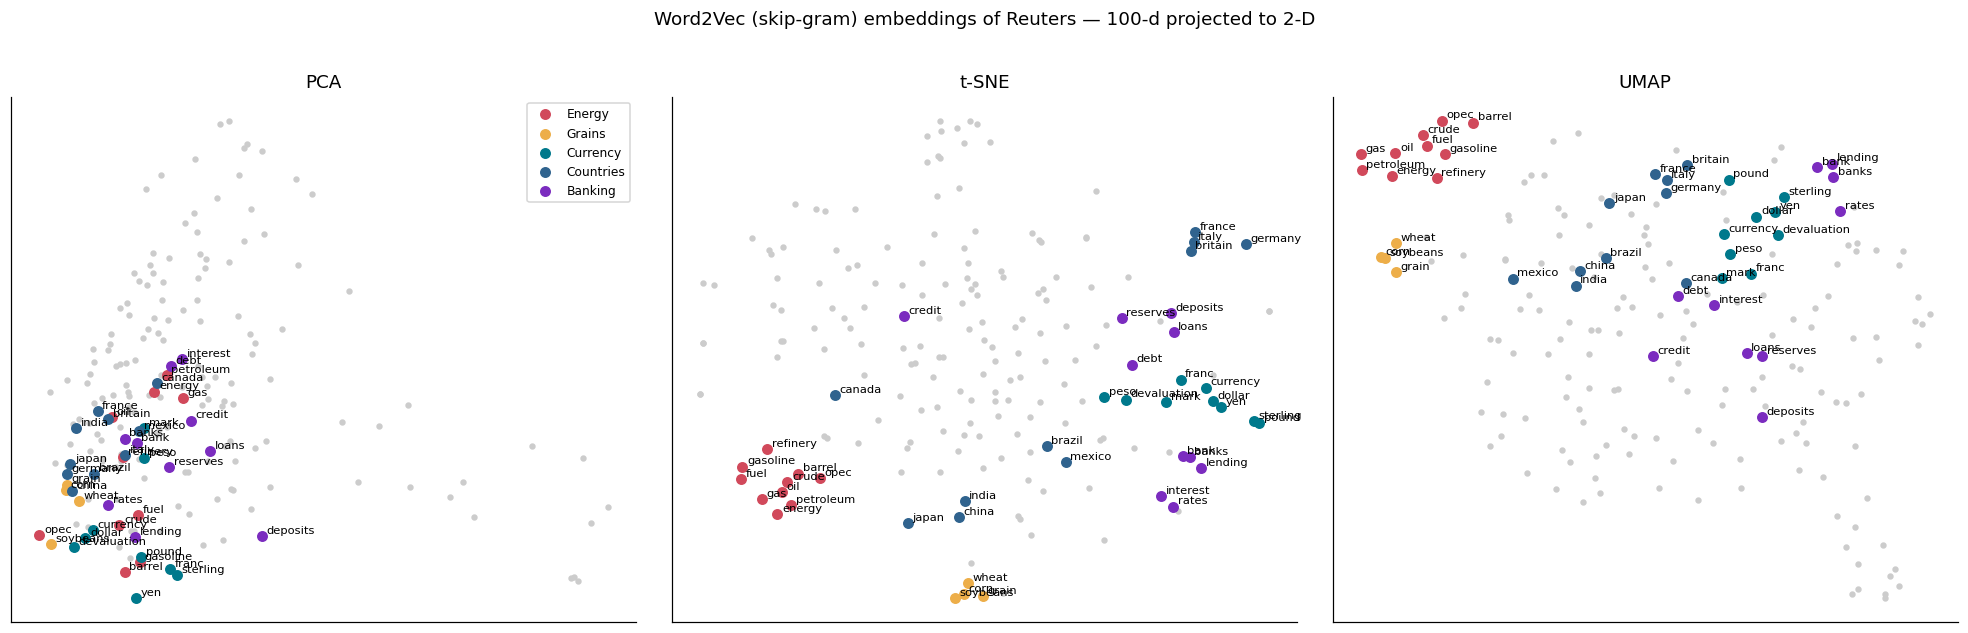

In [23]:
import umap
background = [w for w in w2v_sg.wv.index_to_key[:400] if w not in group_of][:150]
words_viz = labeled + background
Xv = np.stack([w2v_sg.wv[w] for w in words_viz])

proj = {}
proj["PCA"] = PCA(2, random_state=SEED).fit_transform(Xv)
proj["t-SNE"] = TSNE(2, perplexity=20, init="pca", random_state=SEED, max_iter=1500).fit_transform(Xv)
proj["UMAP"] = umap.UMAP(n_neighbors=15, min_dist=0.3, random_state=SEED).fit_transform(Xv)

palette = {"Energy": "#d1495b", "Grains": "#edae49", "Currency": "#00798c", "Countries": "#30638e", "Banking": "#7b2cbf"}
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
for ax, (name, P) in zip(axes, proj.items()):
    ax.scatter(P[len(labeled):, 0], P[len(labeled):, 1], s=10, c="#cccccc")
    for g, c in palette.items():
        ids = [i for i, w in enumerate(words_viz) if group_of.get(w) == g]
        ax.scatter(P[ids, 0], P[ids, 1], s=38, c=c, label=g)
        for i in ids: ax.annotate(words_viz[i], P[i], fontsize=7.5, xytext=(3, 2), textcoords="offset points")
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(loc="best", fontsize=8)
fig.suptitle("Word2Vec (skip-gram) embeddings of Reuters — 100-d projected to 2-D", y=1.02)
plt.tight_layout(); plt.savefig("outputs/fig_word2vec_pca_tsne_umap.png", bbox_inches="tight", dpi=150); plt.show()

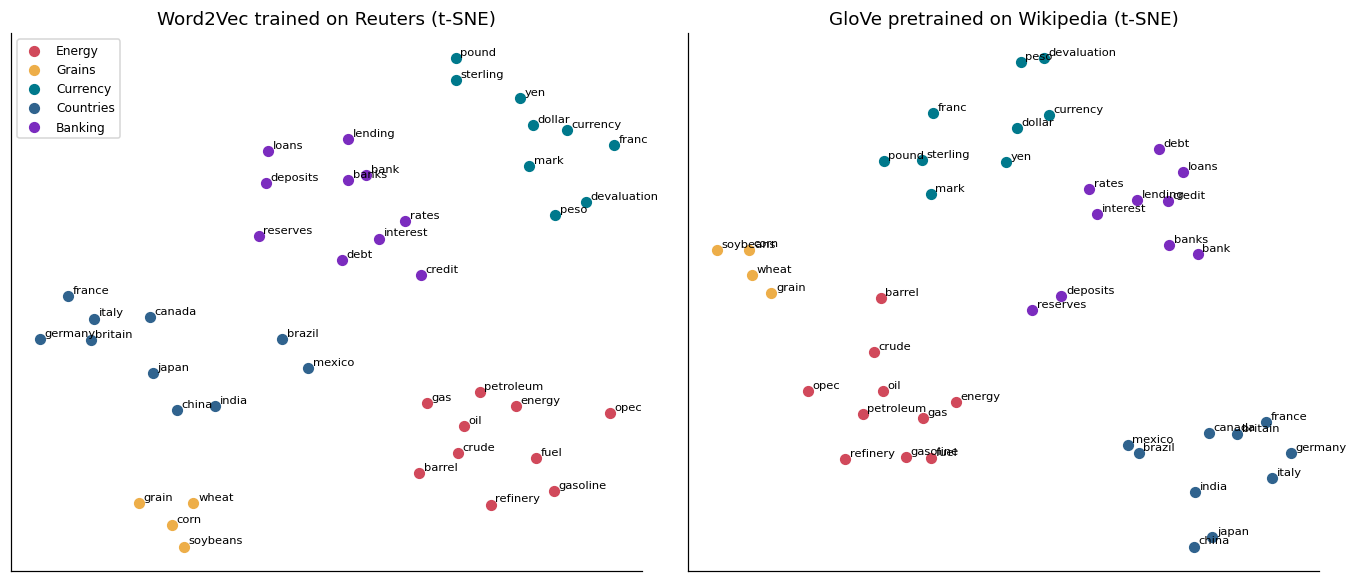

In [24]:
# Cluster quality in the *original* 100-d space: which group does each word's nearest group-word belong to?
# Also a side-by-side t-SNE of GloVe, to see if pretrained vectors cluster the same way.
Xg = np.stack([glove[w] for w in labeled])
Pg = TSNE(2, perplexity=12, init="pca", random_state=SEED, max_iter=1500).fit_transform(Xg)
Pw = TSNE(2, perplexity=12, init="pca", random_state=SEED, max_iter=1500).fit_transform(np.stack([w2v_sg.wv[w] for w in labeled]))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.4))
for ax, P, title in zip(axes, [Pw, Pg], ["Word2Vec trained on Reuters (t-SNE)", "GloVe pretrained on Wikipedia (t-SNE)"]):
    for g, c in palette.items():
        ids = [i for i, w in enumerate(labeled) if group_of[w] == g]
        ax.scatter(P[ids, 0], P[ids, 1], s=40, c=c, label=g)
        for i in ids: ax.annotate(labeled[i], P[i], fontsize=7.5, xytext=(3, 2), textcoords="offset points")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(fontsize=8); plt.tight_layout()
plt.savefig("outputs/fig_w2v_vs_glove_tsne.png", bbox_inches="tight", dpi=150); plt.show()

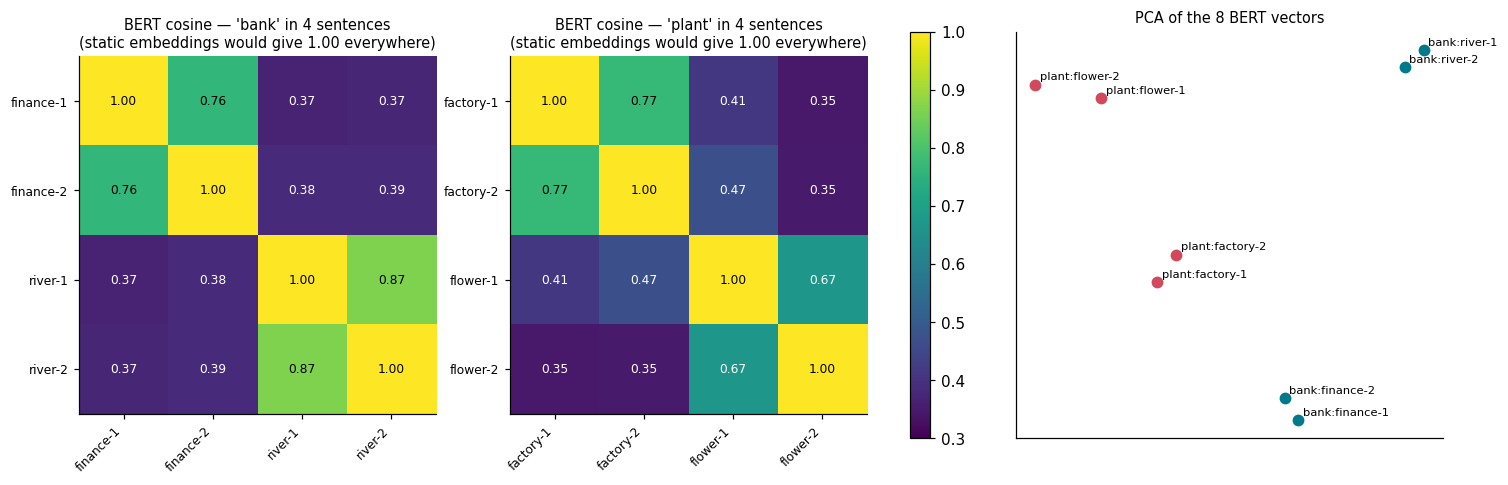

In [25]:
if BERT_OK:
    # Contextual vs static: BERT vectors of 'bank' / 'plant' in four sentences each (PCA to 2-D) and the cosine heat-maps
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.1]})
    for ax, word in zip(axes[:2], contexts):
        names = [n for n, _ in contexts[word]]
        m = ctx_cos[word]
        im = ax.imshow(m, vmin=0.3, vmax=1.0, cmap="viridis")
        ax.set_xticks(range(4)); ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8)
        ax.set_yticks(range(4)); ax.set_yticklabels(names, fontsize=8)
        for i in range(4):
            for j in range(4): ax.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center", color="white" if m[i, j] < 0.75 else "black", fontsize=8)
        ax.set_title(f"BERT cosine — '{word}' in 4 sentences\n(static embeddings would give 1.00 everywhere)", fontsize=9.5)
    plt.colorbar(im, ax=axes[:2], fraction=0.03)
    allv = np.vstack([ctx_vecs["bank"], ctx_vecs["plant"]]); lab = [f"bank:{n}" for n, _ in contexts["bank"]] + [f"plant:{n}" for n, _ in contexts["plant"]]
    P2 = PCA(2, random_state=SEED).fit_transform(allv)
    ax = axes[2]
    for i, l in enumerate(lab):
        ax.scatter(*P2[i], c="#00798c" if l.startswith("bank") else "#d1495b", s=45)
        ax.annotate(l, P2[i], fontsize=7.5, xytext=(3, 3), textcoords="offset points")
    ax.set_title("PCA of the 8 BERT vectors", fontsize=9.5); ax.set_xticks([]); ax.set_yticks([])
    plt.savefig("outputs/fig_bert_contextual.png", bbox_inches="tight", dpi=150); plt.show()

### 8.1 Export for the TensorFlow Embedding Projector
Open <https://projector.tensorflow.org/>, click **Load**, upload `vectors.tsv` (step 1) and `metadata.tsv` (step 2). Then try **PCA / t-SNE / UMAP** in the bottom-left panel, **colour by `group`**, and search a word (e.g. *oil*) to see its nearest neighbours.

In [26]:
proj_words = (labeled + [w for w in w2v_sg.wv.index_to_key[:1500] if w not in group_of])[:1500]
np.savetxt("outputs/projector/vectors.tsv", np.stack([w2v_sg.wv[w] for w in proj_words]), delimiter="\t", fmt="%.5f")
with open("outputs/projector/metadata.tsv", "w") as f:
    f.write("word\tgroup\n")
    for w in proj_words: f.write(f"{w}\t{group_of.get(w, 'other')}\n")
print(f"Exported {len(proj_words)} Word2Vec vectors -> outputs/projector/vectors.tsv + metadata.tsv")

Exported 1500 Word2Vec vectors -> outputs/projector/vectors.tsv + metadata.tsv


## 9. Comparative analysis
### 9.1 Side-by-side nearest neighbours (top-5 by cosine similarity)

In [27]:
names = ["TF-IDF", "LSA (PPMI+SVD)", "Word2Vec (skip-gram)", "Word2Vec (CBOW)", "FastText", "GloVe (pretrained)", "Keras Embedding"]
nbr = neighbour_table(names, QUERY, 5)
nbr.to_csv("outputs/top5_neighbours.csv")
RESULTS["neighbours"] = {q: {n: [(w, round(s, 3)) for w, s in EMB[n].nn(q, 5)] if q in EMB[n] else None for n in names} for q in QUERY}
pd.set_option("display.max_colwidth", 120); nbr

,TF-IDF,LSA (PPMI+SVD),Word2Vec (skip-gram),Word2Vec (CBOW),FastText,GloVe (pretrained),Keras Embedding
query,,,,,,,
oil,"crude (0.45), barrels (0.40), gas (0.38), barrel (0.36), petroleum (0.32)","crude (0.81), petroleum (0.73), barrels (0.71), bpd (0.70), gas (0.68)","crude (0.75), petroleum (0.60), condensate (0.60), liquids (0.60), ekofisk (0.60)","petroleum (0.61), natural (0.55), crudes (0.52), liquids (0.51), fuel (0.49)","crude (0.68), barrels (0.62), unocal (0.62), condensate (0.62), oilfield (0.62)","petroleum (0.79), crude (0.78), gas (0.76), fuel (0.70), energy (0.69)","exxon (0.98), crudes (0.98), opec (0.98), barrels (0.97), refinery (0.97)"
bank,"money (0.43), england (0.38), central (0.37), market (0.36), rate (0.33)","banks (0.79), lending (0.73), chartered (0.72), central (0.72), westminster (0.71)","banks (0.70), central (0.64), satoshi (0.62), lending (0.60), banking (0.60)","banks (0.66), bankers (0.58), governor (0.48), bundesbank (0.47), satoshi (0.46)","banks (0.72), bankverein (0.71), bankhaus (0.68), bankeast (0.68), bankshares (0.65)","banks (0.81), banking (0.75), credit (0.70), investment (0.69), financial (0.68)","banks (0.95), unlikely (0.92), prompted (0.91), requirement (0.90), meeting (0.89)"
dollar,"yen (0.41), currency (0.36), dealers (0.33), tokyo (0.30), japan (0.27)","yen (0.91), currency (0.87), currencies (0.80), mark (0.80), dealers (0.80)","currencies (0.72), yen (0.68), currency (0.65), appreciating (0.64), overvalued (0.63)","currencies (0.60), sterling (0.57), mark (0.55), dollars (0.53), rupiah (0.51)","dollars (0.71), currencies (0.70), eurodollar (0.69), yen (0.66), currency (0.64)","currency (0.76), greenback (0.73), euro (0.73), dollars (0.73), currencies (0.71)","currency (0.99), paris (0.98), auctions (0.97), monetary (0.96), auction (0.96)"
wheat,"tonnes (0.40), agriculture (0.35), soft (0.34), usda (0.33), export (0.31)","barley (0.88), corn (0.83), durum (0.79), flour (0.78), usda (0.77)","barley (0.73), durum (0.69), corn (0.68), usda (0.66), wheats (0.65)","corn (0.69), grains (0.66), barley (0.66), argentina (0.61), grain (0.61)","wheats (0.88), barley (0.74), corn (0.68), eep (0.67), feedgrain (0.66)","corn (0.88), grain (0.85), maize (0.82), soybeans (0.79), soybean (0.78)","pave (0.93), faith (0.93), sudden (0.92), respects (0.92), reopened (0.92)"
japan,"japanese (0.43), yen (0.40), tokyo (0.32), trade (0.30), dealers (0.29)","japanese (0.88), tokyo (0.80), chip (0.78), chipmakers (0.78), microchip (0.78)","japanese (0.70), chipmakers (0.62), reneging (0.60), microchip (0.59), microchips (0.59)","japanese (0.62), tokyo (0.53), chip (0.51), washington (0.46), microchips (0.46)","japanese (0.78), microchips (0.64), microchip (0.63), tokyo (0.62), tadashi (0.58)","japanese (0.80), korea (0.77), tokyo (0.75), china (0.74), indonesia (0.65)","reforms (0.96), moves (0.94), indicators (0.93), way (0.93), countries (0.93)"
trade,"deficit (0.40), surplus (0.39), tariffs (0.35), imports (0.33), exports (0.33)","yeutter (0.84), bilateral (0.78), tariffs (0.78), barriers (0.77), practices (0.77)","counterpart (0.66), outlining (0.63), channon (0.63), lopsided (0.62), yeutter (0.61)","yeutter (0.54), clercq (0.51), invisibles (0.51), gatt (0.50), protectionist (0.44)","yeutter (0.65), bilateral (0.64), countertrade (0.60), unilateral (0.60), imbalance (0.60)","export (0.71), economic (0.71), trading (0.71), commerce (0.71), cooperation (0.69)","israeli (0.98), washington (0.98), practices (0.98), gatt (0.98), chipmakers (0.98)"


### 9.2 A simple quantitative test — neighbour purity@5
For each of the labelled words (Energy, Grains, Currency, Countries, Banking) we look at its 5 nearest neighbours **among the other labelled words only** and count how many belong to the **same** group.
A perfect semantic space scores 1.0; random guessing scores ≈ 0.2. This makes the very different representations directly comparable.

GloVe (pretrained)      0.874
Word2Vec (skip-gram)    0.860
FastText                0.833
Word2Vec (CBOW)         0.819
LSA (PPMI+SVD)          0.800
TF-IDF                  0.656
Keras Embedding         0.553


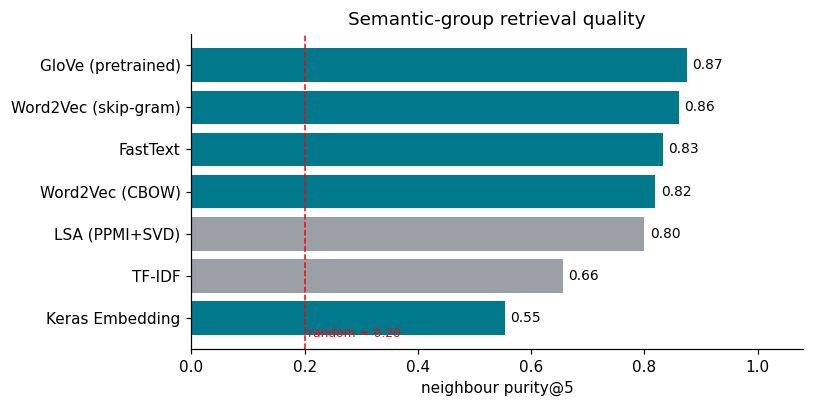

In [28]:
def purity_at_k(emb, k=5):
    hits = []
    for w in labeled:
        nn = emb.nn(w, k, candidates=labeled)
        hits.append(np.mean([group_of[x] == group_of[w] for x, _ in nn]))
    return float(np.mean(hits))
purity = {n: purity_at_k(EMB[n]) for n in names}
pur_df = pd.Series(purity, name="purity@5").sort_values(ascending=False)
print(pur_df.round(3).to_string())
RESULTS["purity"] = purity; RESULTS["groups"] = GROUPS

fig, ax = plt.subplots(figsize=(7.5, 3.8))
colors = {"TF-IDF": "#9aa0a6", "LSA (PPMI+SVD)": "#9aa0a6"}
ax.barh(pur_df.index[::-1], pur_df.values[::-1], color=[colors.get(n, "#00798c") for n in pur_df.index[::-1]])
for i, v in enumerate(pur_df.values[::-1]): ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9)
ax.axvline(0.2, ls="--", c="red", lw=1); ax.text(0.205, -0.45, "random ≈ 0.20", color="red", fontsize=8)
ax.set_xlim(0, 1.08); ax.set_xlabel("neighbour purity@5"); ax.set_title("Semantic-group retrieval quality")
plt.tight_layout(); plt.savefig("outputs/fig_purity.png", dpi=150); plt.show()

### 9.3 Comparison table (semantic representation, OOV handling, context, compute)
Numbers in *Dim*, *Build time* and *purity@5* are **measured in this notebook**; the qualitative columns summarise the theory.

In [29]:
dim = {"One-Hot": f"{len(vocab_toy)} (= |V|)", "BoW / N-grams": f"{X_bow.shape[1]:,} / {X_ng.shape[1]:,}", "TF-IDF": f"{X_tfidf.shape[1]:,} (sparse)",
       "LSA (PPMI+SVD)": "100", "Word2Vec (skip-gram)": "100", "Word2Vec (CBOW)": "100", "FastText": "100", "GloVe (pretrained)": "100",
       "Keras Embedding": "50", "BERT": "768"}
tm = lambda k: f"{timing[k]:.1f}s" if k in timing else "—"
comp = pd.DataFrame([
    ["One-Hot",              "Sparse, count-based", "None (all words orthogonal)", "No",  "No",  "—", dim["One-Hot"], "—", "Very low"],
    ["BoW / N-grams",        "Sparse, count-based", "Weak (co-use in documents)",   "No",  "No",  "—", dim["BoW / N-grams"], tm("BoW + N-grams"), "Low (large memory)"],
    ["TF-IDF",               "Sparse, weighted",    "Weak–moderate (topic level)",  "No",  "No",  f"{purity['TF-IDF']:.2f}", dim["TF-IDF"], tm("TF-IDF"), "Low"],
    ["LSA (PPMI+SVD)",       "Dense, matrix factorisation", "Moderate",           "No",  "No",  f"{purity['LSA (PPMI+SVD)']:.2f}", dim["LSA (PPMI+SVD)"], tm("PPMI + SVD (LSA)"), "Low–medium (SVD)"],
    ["Word2Vec (skip-gram)", "Dense, predictive",   "Strong",                       "No",  "No",  f"{purity['Word2Vec (skip-gram)']:.2f}", dim["Word2Vec (skip-gram)"], tm("Word2Vec skip-gram"), "Medium"],
    ["Word2Vec (CBOW)",      "Dense, predictive",   "Strong (frequent words)",      "No",  "No",  f"{purity['Word2Vec (CBOW)']:.2f}", dim["Word2Vec (CBOW)"], tm("Word2Vec CBOW"), "Medium (fastest W2V)"],
    ["FastText",             "Dense, sub-word",     "Strong",                       "Yes (char n-grams)", "No", f"{purity['FastText']:.2f}", dim["FastText"], tm("FastText"), "Medium–high"],
    ["GloVe (pretrained)",   "Dense, global counts","Strong (general English)",     "No",  "No",  f"{purity['GloVe (pretrained)']:.2f}", dim["GloVe (pretrained)"], f"{tm('GloVe (load pretrained)')} (download)", "Low to use"],
    ["Keras Embedding",      "Dense, task-trained", "Task-specific",                "No",  "No",  f"{purity['Keras Embedding']:.2f}", dim["Keras Embedding"], tm("Keras Embedding (12 epochs)"), "Low–medium"],
    ["BERT",                 "Dense, contextual",   "Very strong, sense-aware",     "Yes (WordPiece)", "Yes", "n/a (per-sentence)", dim["BERT"], "pretrained", "High (110 M params)"],
], columns=["Technique", "Type", "Semantic representation", "OOV handling", "Contextual", "purity@5", "Dim", "Build time", "Compute / memory"]).set_index("Technique")
comp.to_csv("outputs/comparison_table.csv")
RESULTS["timing"] = timing
json.dump(RESULTS, open("outputs/results.json", "w"), indent=1, default=str)
comp

,Type,Semantic representation,OOV handling,Contextual,purity@5,Dim,Build time,Compute / memory
Technique,,,,,,,,
One-Hot,"Sparse, count-based",None (all words orthogonal),No,No,—,8 (= |V|),—,Very low
BoW / N-grams,"Sparse, count-based",Weak (co-use in documents),No,No,—,"8,312 / 10,483",6.6s,Low (large memory)
TF-IDF,"Sparse, weighted",Weak–moderate (topic level),No,No,0.66,"8,312 (sparse)",1.6s,Low
LSA (PPMI+SVD),"Dense, matrix factorisation",Moderate,No,No,0.80,100,5.9s,Low–medium (SVD)
Word2Vec (skip-gram),"Dense, predictive",Strong,No,No,0.86,100,113.7s,Medium
Word2Vec (CBOW),"Dense, predictive",Strong (frequent words),No,No,0.82,100,19.2s,Medium (fastest W2V)
FastText,"Dense, sub-word",Strong,Yes (char n-grams),No,0.83,100,117.8s,Medium–high
GloVe (pretrained),"Dense, global counts",Strong (general English),No,No,0.87,100,57.4s (download),Low to use
Keras Embedding,"Dense, task-trained",Task-specific,No,No,0.55,50,12.7s,Low–medium


## 10. Conclusions
1. **Traditional vectors** (One-Hot, BoW, TF-IDF) are interpretable and cheap but sparse and high-dimensional; similarity only reflects *which documents a word appears in*.
2. **Predictive embeddings** (Word2Vec, FastText) and **matrix-factorisation** (LSA, GloVe) compress usage statistics into 50–300 dense dimensions and capture semantic groups such as energy, grains, currencies and countries (see purity@5 and the t-SNE/UMAP plots).
3. **FastText** is the only static model here that can embed unseen word forms; Word2Vec/GloVe fail with a `KeyError`.
4. **Keras `Embedding`** vectors are optimised for the downstream task (topic classification), so their neighbours follow topic usage rather than general meaning.
5. **BERT** gives a different vector for every occurrence of a word, so *bank* (finance) and *bank* (river) are separated — something no static embedding can do — at the price of far higher compute.

*Files produced:* `outputs/*.png` (figures), `outputs/top5_neighbours.csv`, `outputs/comparison_table.csv`, `outputs/results.json`, `outputs/projector/{vectors,metadata}.tsv`.